In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [8]:
df = pd.read_csv('/home/ved/Downloads/sales_data_sample.csv', encoding='latin')

print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [9]:
print("Shape of dataset:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Shape of dataset: (2823, 25)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   obje

In [10]:
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']]

print(X.head())
print("\nMissing values:")
print(X.isnull().sum())

   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95

Missing values:
QUANTITYORDERED    0
PRICEEACH          0
SALES              0
MSRP               0
dtype: int64


In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.52289086  0.5969775  -0.37082523 -0.14224584]
 [-0.11220131 -0.11445035 -0.42789707 -0.14224584]
 [ 0.60650538  0.54938372  0.17944282 -0.14224584]
 [ 1.01719493 -0.01975856  0.10470098 -0.14224584]
 [ 1.42788447  0.81015797  0.89673966 -0.14224584]]


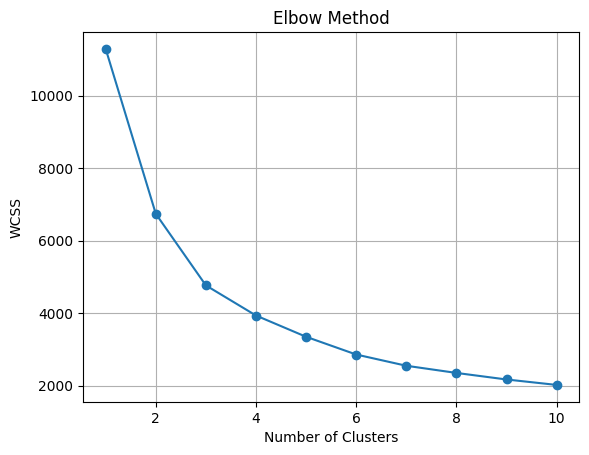

In [12]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [13]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

y_kmeans = kmeans.fit_predict(X_scaled)

df['Cluster'] = y_kmeans

print(df[['SALES', 'QUANTITYORDERED', 'Cluster']].head(10))

     SALES  QUANTITYORDERED  Cluster
0  2871.00               30        2
1  2765.90               34        2
2  3884.34               41        1
3  3746.70               45        1
4  5205.27               49        1
5  3479.76               36        2
6  2497.77               29        2
7  5512.32               48        1
8  2168.54               22        2
9  4708.44               41        1


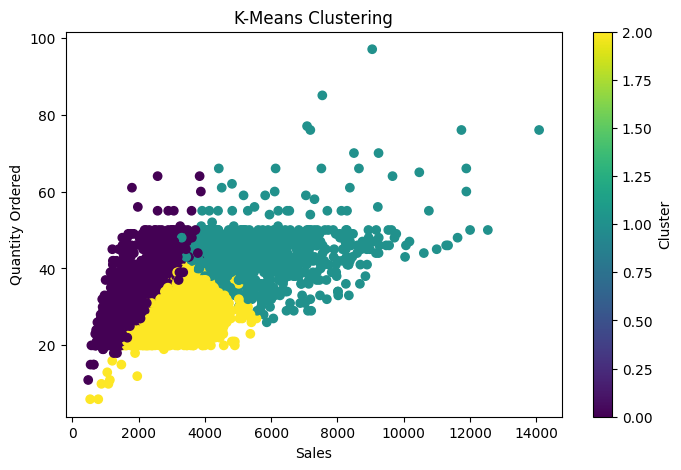

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(df['SALES'], df['QUANTITYORDERED'],
            c=df['Cluster'], cmap='viridis')

plt.xlabel('Sales')
plt.ylabel('Quantity Ordered')
plt.title('K-Means Clustering')
plt.colorbar(label='Cluster')
plt.show()

In [15]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')

y_hc = hc.fit_predict(X_scaled)

df['Hierarchical_Cluster'] = y_hc

print(df[['SALES', 'QUANTITYORDERED', 'Hierarchical_Cluster']].head(10))

     SALES  QUANTITYORDERED  Hierarchical_Cluster
0  2871.00               30                     2
1  2765.90               34                     2
2  3884.34               41                     0
3  3746.70               45                     0
4  5205.27               49                     1
5  3479.76               36                     0
6  2497.77               29                     2
7  5512.32               48                     1
8  2168.54               22                     2
9  4708.44               41                     1


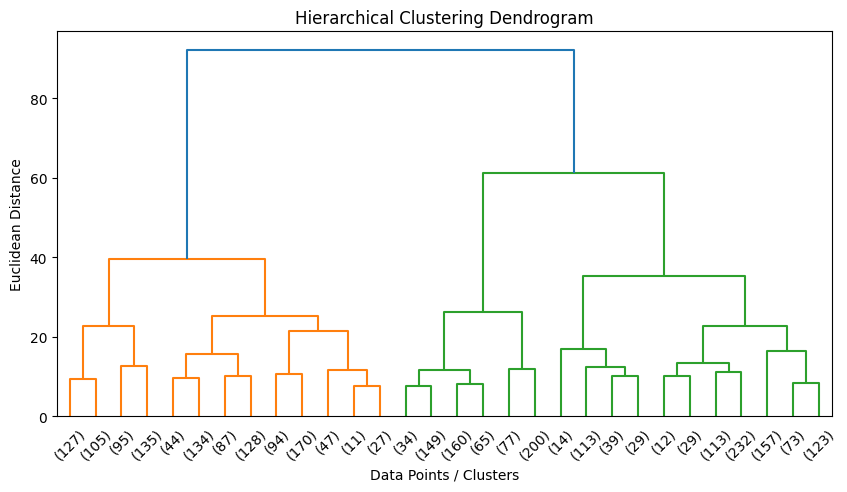

In [16]:
plt.figure(figsize=(10, 5))

Z = linkage(X_scaled, method='ward')

dendrogram(Z, truncate_mode='lastp', p=30)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points / Clusters')
plt.ylabel('Euclidean Distance')
plt.show()

In [17]:
print("K-Means Cluster Sizes:")
print(df['Cluster'].value_counts().sort_index())

print("\nHierarchical Cluster Sizes:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

K-Means Cluster Sizes:
Cluster
0    975
1    852
2    996
Name: count, dtype: int64

Hierarchical Cluster Sizes:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


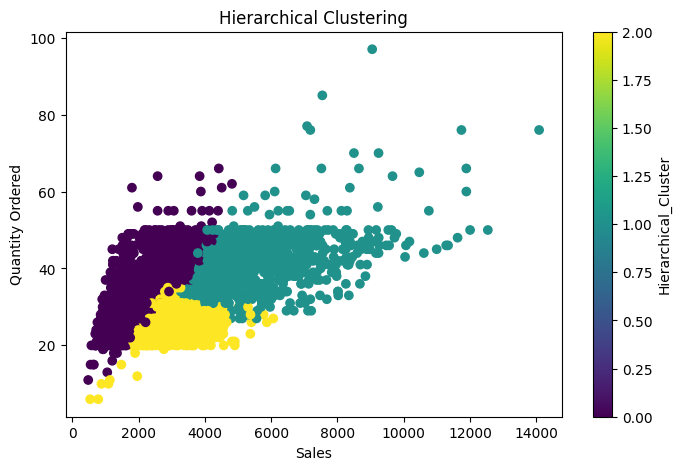

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['SALES'], 
    df['QUANTITYORDERED'], 
    c=df['Hierarchical_Cluster'], 
    cmap='viridis'
)

plt.xlabel('Sales')
plt.ylabel('Quantity Ordered')
plt.title('Hierarchical Clustering')
plt.colorbar(label='Hierarchical_Cluster')
plt.show()